# Example of the aitlas toolbox in the context of object detection in remote sensing images

## Import the required packages

In [ ]:
import warnings
warnings.filterwarnings("ignore", category=UserWarning) 
warnings.filterwarnings("ignore", category=DeprecationWarning) 

from aitlas.datasets import LEVIRDataset 
from aitlas.transforms import Resize
from aitlas.utils import image_loader
from aitlas.models import FasterRCNN

## Visualize images and objects witn bounding boxes

Total number of patches: 1185


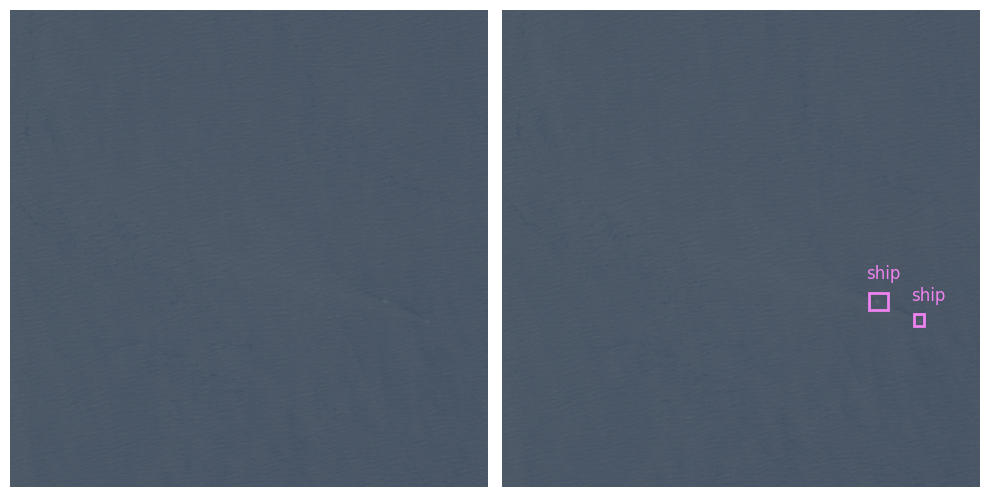

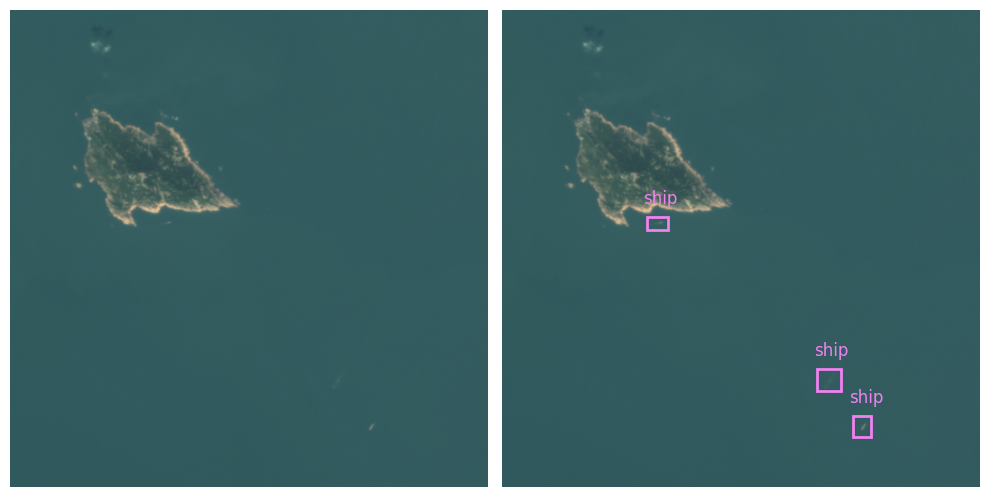

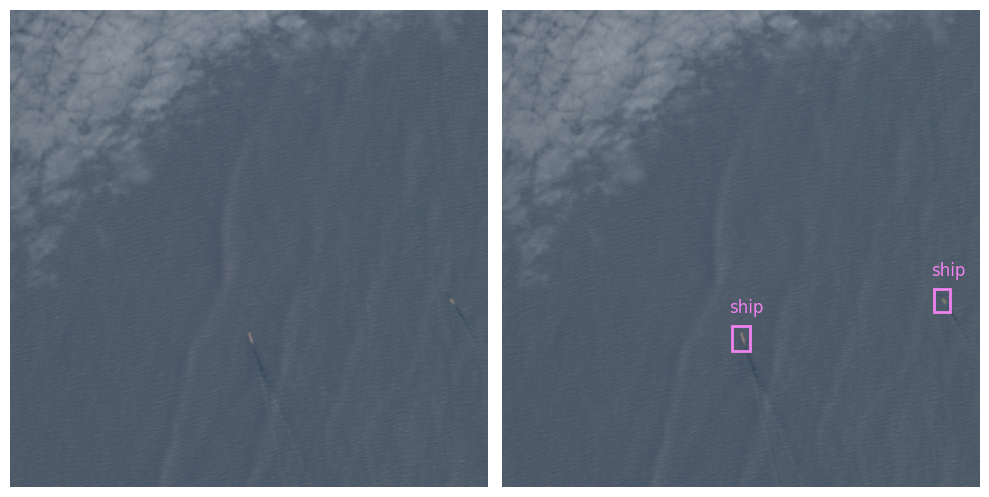

In [5]:
dataset_config = {
    "data_dir": "/home/dragik/data/FAIR_EO/LEVIR/train/images/",
    "annotation_dir": "/home/dragik/data/FAIR_EO/LEVIR/train/labels/",
}
dataset = LEVIRDataset(dataset_config)

print(f"Total number of patches: {len(dataset)}")
dataset.show_image(2);
dataset.show_image(10);
dataset.show_image(100);

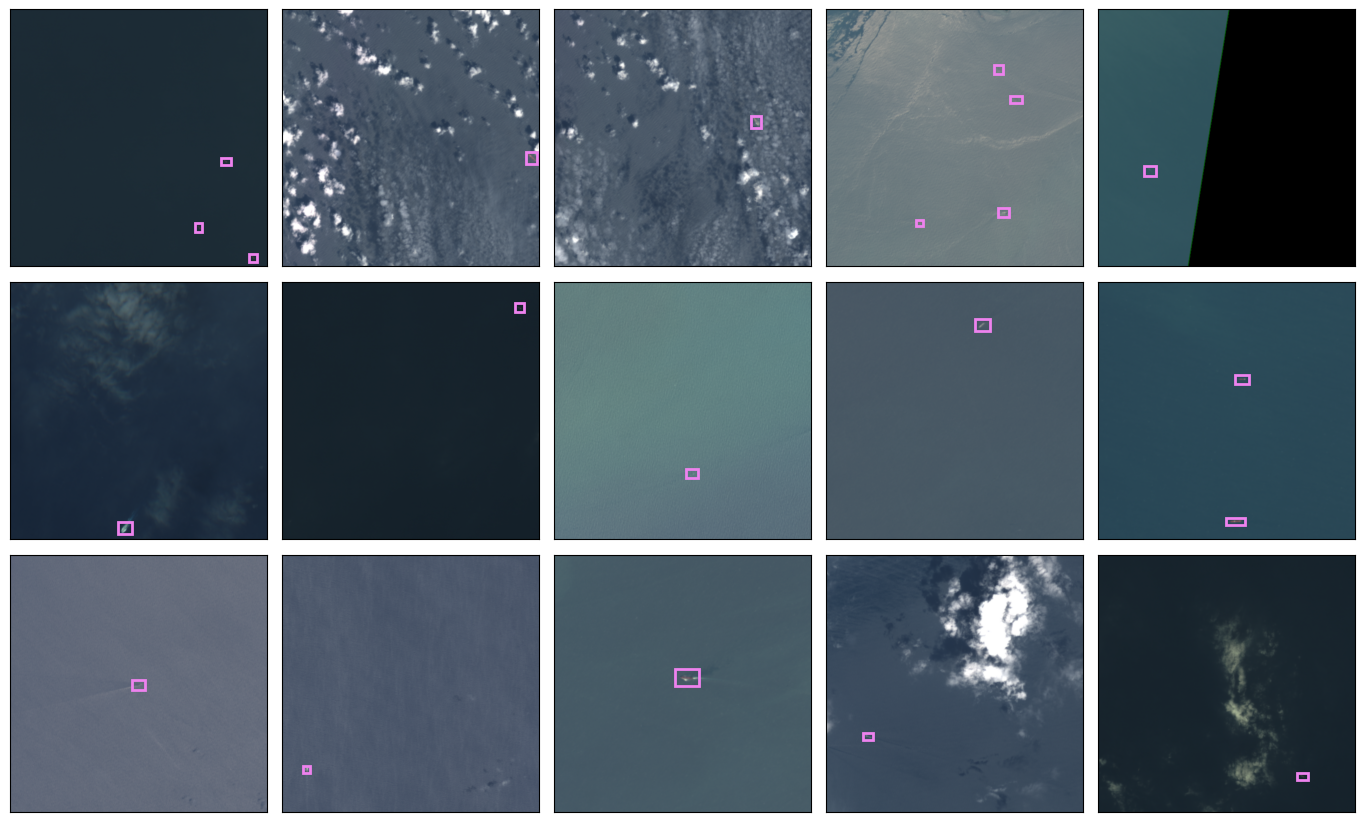

In [17]:
dataset.show_batch(15);

In [6]:
dataset.data_distribution_table()

,Label,Count
0,ship,2002


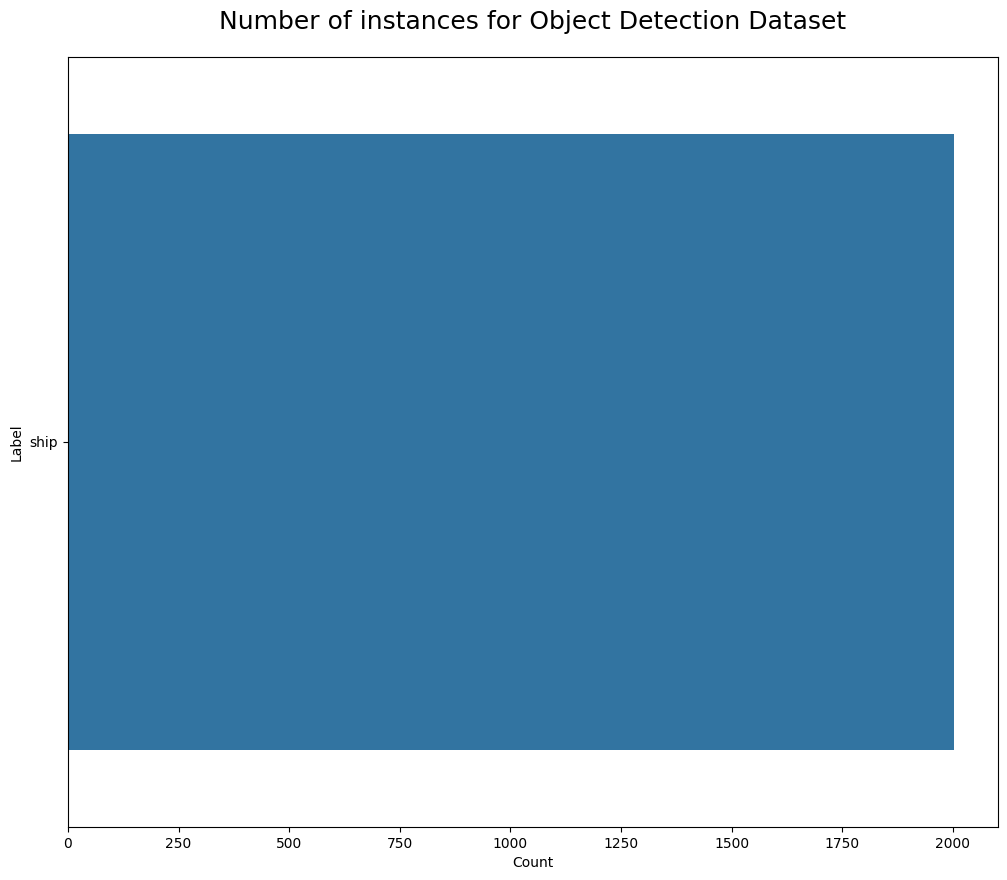

In [19]:
dataset.data_distribution_barchart();

## Load train data

In [7]:
train_dataset_config = {
    "batch_size": 8,
    "shuffle": True,
    "data_dir": "/home/dragik/data/FAIR_EO/LEVIR/train/images/",
    "annotation_dir": "/home/dragik/data/FAIR_EO/LEVIR/train/labels/",
    "joint_transforms": ["aitlas.transforms.ResizeToTensorV2"]
}
train_dataset = LEVIRDataset(train_dataset_config)

print(f"Total number of train images: {len(train_dataset)}")

Total number of train images: 1185


## Create the model

In [8]:
epochs = 10
model_directory = "/home/dragik/data/FAIR_EO/LEVIR/experiments/"
model_config = {
    "num_classes": 2,
    "learning_rate": 0.0001,
    "pretrained": True,
    "metrics": ["map"]
}

model = FasterRCNN(model_config)
model.prepare()

## Start the training

In [9]:
model.train_model(
    train_dataset=train_dataset,
    epochs=epochs,
    model_directory=model_directory,
    run_id='1'
);

2025-04-28 07:29:47,582 INFO Starting training.
training: 100%|██████████| 149/149 [01:14<00:00,  2.00it/s]
2025-04-28 07:31:02,287 INFO epoch: 1, time: 75, loss:  0.20028
testing on train set: 100%|██████████| 149/149 [00:54<00:00,  2.72it/s]
2025-04-28 07:32:00,394 INFO map:0.3169745206832886, map_50:0.7852853536605835, map_75:0.1639501005411148, map_small:0.31872817873954773, map_medium:0.11388731747865677, map_large:-1.0, mar_1:0.2566933035850525, mar_10:0.4063436686992645, mar_100:0.41578420996665955, mar_small:0.4184979796409607, mar_medium:0.11666666716337204, mar_large:-1.0, map_per_class:0.3169745206832886, mar_100_per_class:0.41578420996665955, classes:1.0
training: 100%|██████████| 149/149 [00:57<00:00,  2.61it/s]
2025-04-28 07:32:57,420 INFO epoch: 2, time: 57, loss:  0.16202
testing on train set: 100%|██████████| 149/149 [00:41<00:00,  3.57it/s]
2025-04-28 07:33:40,482 INFO map:0.38142743706703186, map_50:0.8595276474952698, map_75:0.24306100606918335, map_small:0.38201764

## Evaluate the model

In [10]:
test_dataset_config = {
    "batch_size": 8,
    "shuffle": False,
    "data_dir": "/home/dragik/data/FAIR_EO/LEVIR/val/images/",
    "annotation_dir": "/home/dragik/data/FAIR_EO/LEVIR/val/labels/",
    "joint_transforms": ["aitlas.transforms.ResizeToTensorV2"]
}

test_dataset = LEVIRDataset(test_dataset_config)
print(f"Total number of test images: {len(test_dataset)}")

model = FasterRCNN(model_config)
model.prepare()
model.running_metrics.reset()
model_path = "/home/dragik/data/FAIR_EO/LEVIR/experiments/checkpoint.pth.tar"
model.evaluate(dataset=test_dataset, model_path=model_path)
model.running_metrics.get_scores(model.metrics)

Total number of test images: 394


2025-04-28 07:49:36,332 INFO Loading checkpoint /home/dragik/data/FAIR_EO/LEVIR/experiments/checkpoint.pth.tar
2025-04-28 07:49:37,228 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/LEVIR/experiments/checkpoint.pth.tar at epoch 11
testing on test set: 100%|██████████| 50/50 [00:20<00:00,  2.40it/s]


[{'map': 0.31641024351119995,
  'map_50': 0.7807109951972961,
  'map_75': 0.18670381605625153,
  'map_small': 0.3157585561275482,
  'map_medium': 0.42717114090919495,
  'map_large': -1.0,
  'mar_1': 0.2718797028064728,
  'mar_10': 0.40195488929748535,
  'mar_100': 0.4057142734527588,
  'mar_small': 0.40500760078430176,
  'mar_medium': 0.4833333194255829,
  'mar_large': -1.0,
  'map_per_class': 0.31641024351119995,
  'mar_100_per_class': 0.4057142734527588,
  'classes': 1.0}]

## Predictions

2025-04-28 07:57:15,834 INFO Loading checkpoint /home/dragik/data/FAIR_EO/LEVIR/experiments/checkpoint.pth.tar
2025-04-28 07:57:16,085 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/LEVIR/experiments/checkpoint.pth.tar at epoch 11


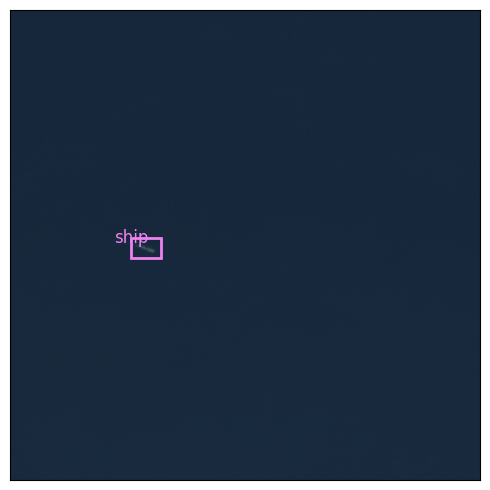

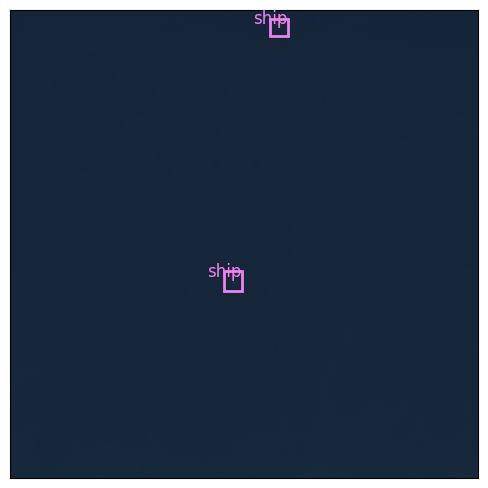

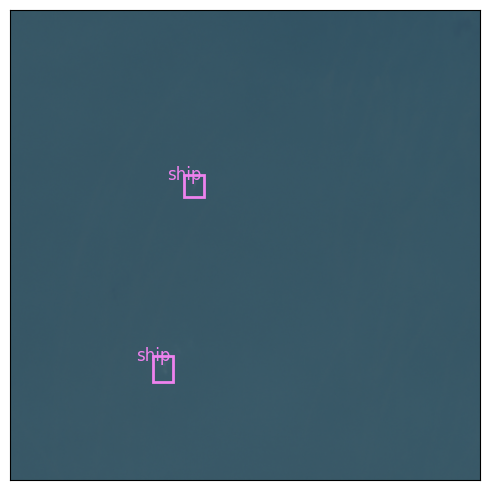

In [16]:
model_config = {
    "num_classes": 2,
    "learning_rate": 0.0001,
    "pretrained": True,
    "metrics": ["map"]
}
model = FasterRCNN(model_config)
model.prepare()

model_path = "/home/dragik/data/FAIR_EO/LEVIR/experiments/checkpoint.pth.tar"
labels = ["no-data","ship"]
transform = Resize()
model.load_model(model_path)

image = image_loader('/home/dragik/data/FAIR_EO/LEVIR/test/images/GF1_WFV4_E124.0_N33.5_20131122_L1A0000115971_512_2560.png')
fig = model.detect_objects(image, labels, transform)

image = image_loader('/home/dragik/data/FAIR_EO/LEVIR/test/images/GF1_WFV4_E124.0_N33.5_20131122_L1A0000115971_2560_2560.png')
fig = model.detect_objects(image, labels, transform)

image = image_loader('/home/dragik/data/FAIR_EO/LEVIR/test/images/GF1_WFV4_E124.0_N33.5_20131122_L1A0000115971_4608_11264.png')
fig = model.detect_objects(image, labels, transform)